# Logistic Regression from Scratch — COVID-19 Test Result Prediction

A from-scratch NumPy implementation of Logistic Regression (gradient descent, binary cross-entropy loss) applied to a CDC BRFSS-style health survey dataset, predicting self-reported COVID-19 test results from demographic and health indicators. Includes manual metrics (accuracy/precision/recall), an ROC curve computed from scratch, and a comparison against scikit-learn's baseline.


In [2]:
from logistic_regression import LogisticRegression

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_curve,
    auc,
    confusion_matrix
)
from sklearn.preprocessing import OneHotEncoder
import seaborn as sns

In [3]:
df = pd.read_csv("covid_survey.csv")

print(df.head())
print(df.shape)

     State     Sex GeneralHealth  PhysicalHealthDays  MentalHealthDays  \
0  Alabama  Female     Very good                 0.0               0.0   
1  Alabama  Female     Excellent                 0.0               0.0   
2  Alabama  Female     Very good                 2.0               3.0   
3  Alabama  Female     Excellent                 0.0               0.0   
4  Alabama  Female          Fair                 2.0               0.0   

                                     LastCheckupTime PhysicalActivities  \
0  Within past year (anytime less than 12 months ...                 No   
1                                                NaN                 No   
2  Within past year (anytime less than 12 months ...                Yes   
3  Within past year (anytime less than 12 months ...                Yes   
4  Within past year (anytime less than 12 months ...                Yes   

   SleepHours RemovedTeeth HadHeartAttack  ... HeightInMeters  \
0         8.0          NaN             

In [4]:
print(df.info())
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 445132 entries, 0 to 445131
Data columns (total 40 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   State                      445132 non-null  object 
 1   Sex                        445132 non-null  object 
 2   GeneralHealth              443934 non-null  object 
 3   PhysicalHealthDays         434205 non-null  float64
 4   MentalHealthDays           436065 non-null  float64
 5   LastCheckupTime            436824 non-null  object 
 6   PhysicalActivities         444039 non-null  object 
 7   SleepHours                 439679 non-null  float64
 8   RemovedTeeth               433772 non-null  object 
 9   HadHeartAttack             442067 non-null  object 
 10  HadAngina                  440727 non-null  object 
 11  HadStroke                  443575 non-null  object 
 12  HadAsthma                  443359 non-null  object 
 13  HadSkinCancer              44

In [5]:
print(df['CovidPos'].unique())

['No' 'Yes' nan
 'Tested positive using home test without a health professional']


In [6]:
#drop rows where the target is missing
df = df.dropna(subset=['CovidPos'])

# Define(X) (y)
X = df.drop(columns=["CovidPos"])
y = df["CovidPos"].map({
    "No": 0, 
    "Yes": 1, 
    "Tested positive using home test without a health professional": 1
})

y = y.values

Data split

In [7]:
#stratification -> training set and test set get the same percentage of positive cases.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
X_train = X_train.copy()
X_test = X_test.copy()
print(X_train.shape, X_test.shape)

(315494, 39) (78874, 39)


In [ ]:
Missing values (only train set)

In [8]:
num_cols = X_train.select_dtypes(include=['float64', 'int64']).columns
cat_cols = X_train.select_dtypes(include=['object']).columns

train_medians = X_train[num_cols].median()
train_modes = X_train[cat_cols].mode().iloc[0]

X_train[num_cols] = X_train[num_cols].fillna(train_medians)
X_test[num_cols] = X_test[num_cols].fillna(train_medians)

X_train[cat_cols] = X_train[cat_cols].fillna(train_modes)
X_test[cat_cols] = X_test[cat_cols].fillna(train_modes)

Encode categorical data

In [9]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop='first')

X_train_encoded_cat = encoder.fit_transform(X_train[cat_cols])
X_test_encoded_cat  = encoder.transform(X_test[cat_cols])

#  numerical and encoded categorical -> back into single arrays
X_train_final = np.hstack((X_train[num_cols].values, X_train_encoded_cat))
X_test_final  = np.hstack((X_test[num_cols].values, X_test_encoded_cat))

In [10]:
# (Using ONLY Train statistics)
train_mean_array = np.mean(X_train_final, axis=0)
train_std_array  = np.std(X_train_final, axis=0) + 1e-8

X_train_scaled = (X_train_final - train_mean_array) / train_std_array
X_test_scaled  = (X_test_final - train_mean_array) / train_std_array

print(f"Final Training Features Shape: {X_train_scaled.shape}")
print(f"Final Testing Features Shape: {X_test_scaled.shape}")

Final Training Features Shape: (315494, 120)
Final Testing Features Shape: (78874, 120)


In [11]:
# Initialize two separate models
model_slow = LogisticRegression()
model_fast = LogisticRegression()

# Train the first model
print("Training model_slow (lr=0.1)...")
model_slow.fit(X_train_scaled, y_train, epochs = 1000, learning_rate=0.1)

# Train the second model
print("Training model_fast (lr=0.5)...")
model_fast.fit(X_train_scaled, y_train,epochs = 1000, learning_rate=0.5)

Training model_slow (lr=0.1)...
Epoch    0 | Loss: 0.693147
Epoch  100 | Loss: 0.598172
Epoch  200 | Loss: 0.595620
Epoch  300 | Loss: 0.594934
Epoch  400 | Loss: 0.594553
Epoch  500 | Loss: 0.594309
Epoch  600 | Loss: 0.594142
Epoch  700 | Loss: 0.594025
Epoch  800 | Loss: 0.593941
Epoch  900 | Loss: 0.593878
Training Complete | Final Loss: 0.593831
Training model_fast (lr=0.5)...
Epoch    0 | Loss: 0.693147
Epoch  100 | Loss: 0.594304
Epoch  200 | Loss: 0.593830
Epoch  300 | Loss: 0.593713
Epoch  400 | Loss: 0.593674
Epoch  500 | Loss: 0.593660
Epoch  600 | Loss: 0.593653
Epoch  700 | Loss: 0.593649
Epoch  800 | Loss: 0.593646
Epoch  900 | Loss: 0.593644
Training Complete | Final Loss: 0.593642


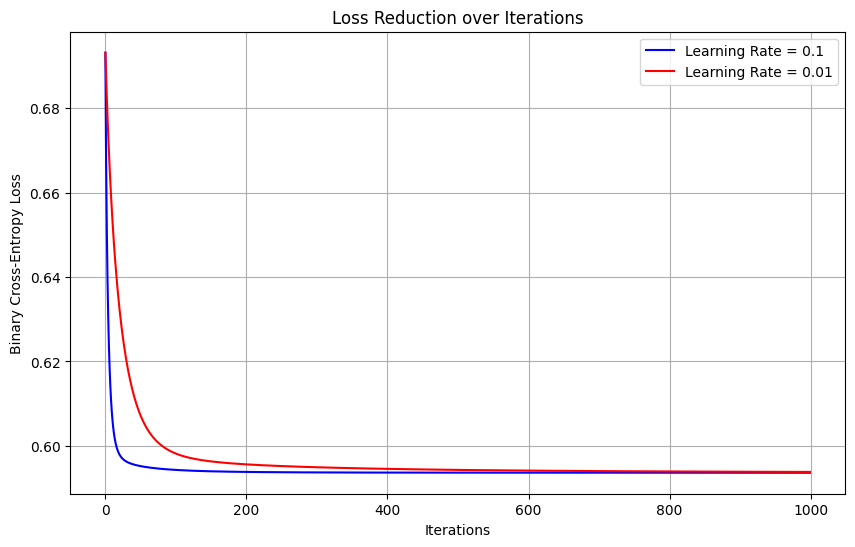

In [17]:
plt.figure(figsize=(10, 6))
plt.plot(model_fast.loss_history, label='Learning Rate = 0.1', color='blue')
plt.plot(model_slow.loss_history, label='Learning Rate = 0.01', color='red')
plt.title('Loss Reduction over Iterations')
plt.xlabel('Iterations')
plt.ylabel('Binary Cross-Entropy Loss')
plt.legend()
plt.grid(True)
plt.show()

In [12]:
def evaluate_model_performance(y_true, y_pred, model_label="Model"):
    # flat NumPy arrays to prevent dimension mismatch
    y_true_flat = np.asarray(y_true).reshape(-1)
    y_pred_flat = np.asarray(y_pred).reshape(-1)
    
    tp = np.sum((y_true_flat == 1) & (y_pred_flat == 1))
    tn = np.sum((y_true_flat == 0) & (y_pred_flat == 0))
    fp = np.sum((y_true_flat == 0) & (y_pred_flat == 1))
    fn = np.sum((y_true_flat == 1) & (y_pred_flat == 0))
    
    # Calculate metrics with inline safety guards for zero denominators
    total_samples = tp + tn + fp + fn
    accuracy = (tp + tn) / total_samples if total_samples > 0 else 0.0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    
    print(f"=== {model_label} ===")
    print(f"Accuracy:  {accuracy * 100:.4f}%")
    print(f"Precision: {precision * 100:.4f}%")
    print(f"Recall:    {recall * 100:.4f}%")
    print(f"Counts:    [TP: {tp}, TN: {tn}, FP: {fp}, FN: {fn}]\n")
    
    #return {
      #  "accuracy": accuracy,
       # "precision": precision,
        #"recall": recall,
        #"confusion_matrix": (tp, tn, fp, fn)
    #}

The models Accuracy - Precision - Recall

In [13]:
y_pred = model_fast.predict(X_test_scaled)
evaluate_model_performance(y_test, y_pred, model_label="Model with Learning Rate of 0.5")

y_pred = model_slow.predict(X_test_scaled)
evaluate_model_performance(y_test, y_pred, model_label="Model with Learning Rate of 0.1")

=== Model with Learning Rate of 0.5 ===
Accuracy:  68.8516%
Precision: 53.4551%
Recall:    9.1783%
Counts:    [TP: 2282, TN: 52024, FP: 1987, FN: 22581]

=== Model with Learning Rate of 0.1 ===
Accuracy:  68.8452%
Precision: 53.6070%
Recall:    8.6675%
Counts:    [TP: 2155, TN: 52146, FP: 1865, FN: 22708]



ROC curve (NumPy)

In [14]:
def np_roc_curve(model, X, y, num_thresholds=100):
    y_probs = model.predict_proba(X).reshape(-1)
    y_true = y.reshape(-1)

    thresholds = np.linspace(0, 1, num_thresholds)

    tpr_list = []
    fpr_list = []

    for threshold in thresholds:

        y_pred = np.where(y_probs >= threshold, 1, 0)

        tp = np.sum((y_true == 1) & (y_pred == 1))
        fp = np.sum((y_true == 0) & (y_pred == 1))
        tn = np.sum((y_true == 0) & (y_pred == 0))
        fn = np.sum((y_true == 1) & (y_pred == 0))

        tpr = tp / (tp + fn) if (tp + fn) > 0 else 0
        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

        tpr_list.append(tpr)
        fpr_list.append(fpr)

    return np.array(fpr_list), np.array(tpr_list)

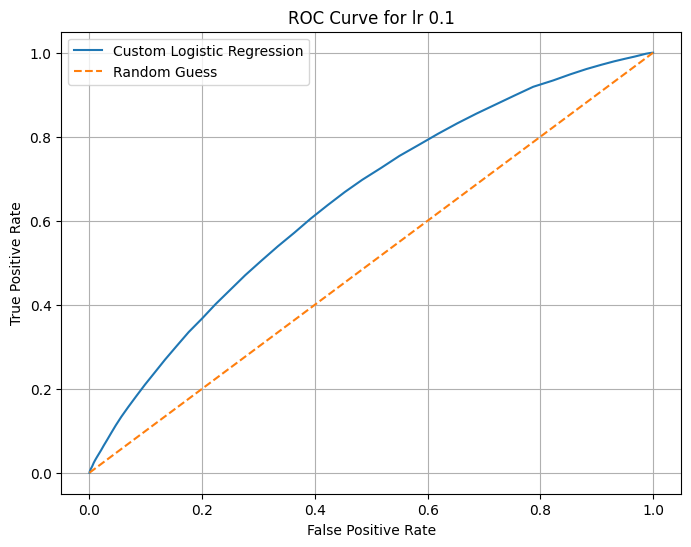

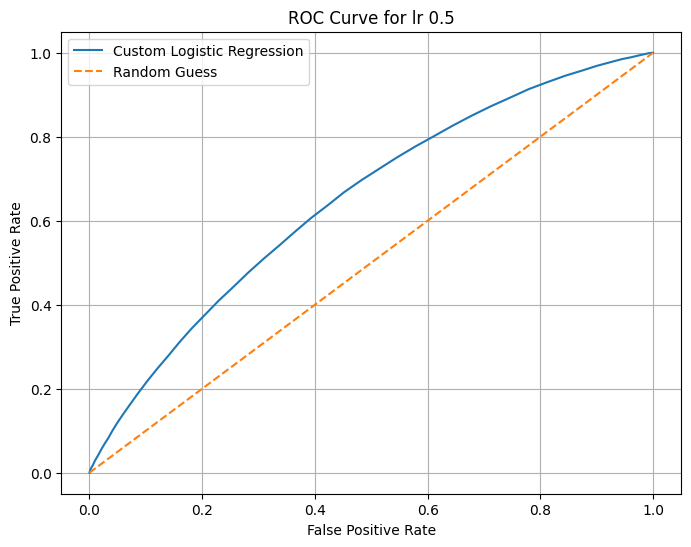

In [15]:
fpr, tpr = np_roc_curve(model_slow, X_test_scaled, y_test)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label="Custom Logistic Regression")
plt.plot([0,1], [0,1], "--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for lr 0.1")
plt.legend()
plt.grid(True)

plt.show()

'''second model'''

fpr, tpr = np_roc_curve(model_fast, X_test_scaled, y_test)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label="Custom Logistic Regression")
plt.plot([0,1], [0,1], "--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for lr 0.5")
plt.legend()
plt.grid(True)

plt.show()

### Comparing to scikit-learn's LogisticRegression

In [16]:
from sklearn.linear_model import LogisticRegression

sklearn_model = LogisticRegression(penalty=None, max_iter=1000, random_state=42)
sklearn_model.fit(X_train_scaled, y_train.reshape(-1))
y_pred_sklearn = sklearn_model.predict(X_test_scaled)
metrics_sklearn = evaluate_model_performance(y_test, y_pred_sklearn, "Scikit-Learn Baseline")

=== Scikit-Learn Baseline ===
Accuracy:  68.8491%
Precision: 53.4301%
Recall:    9.1783%
Counts:    [TP: 2282, TN: 52022, FP: 1989, FN: 22581]



### Correlation Matrix

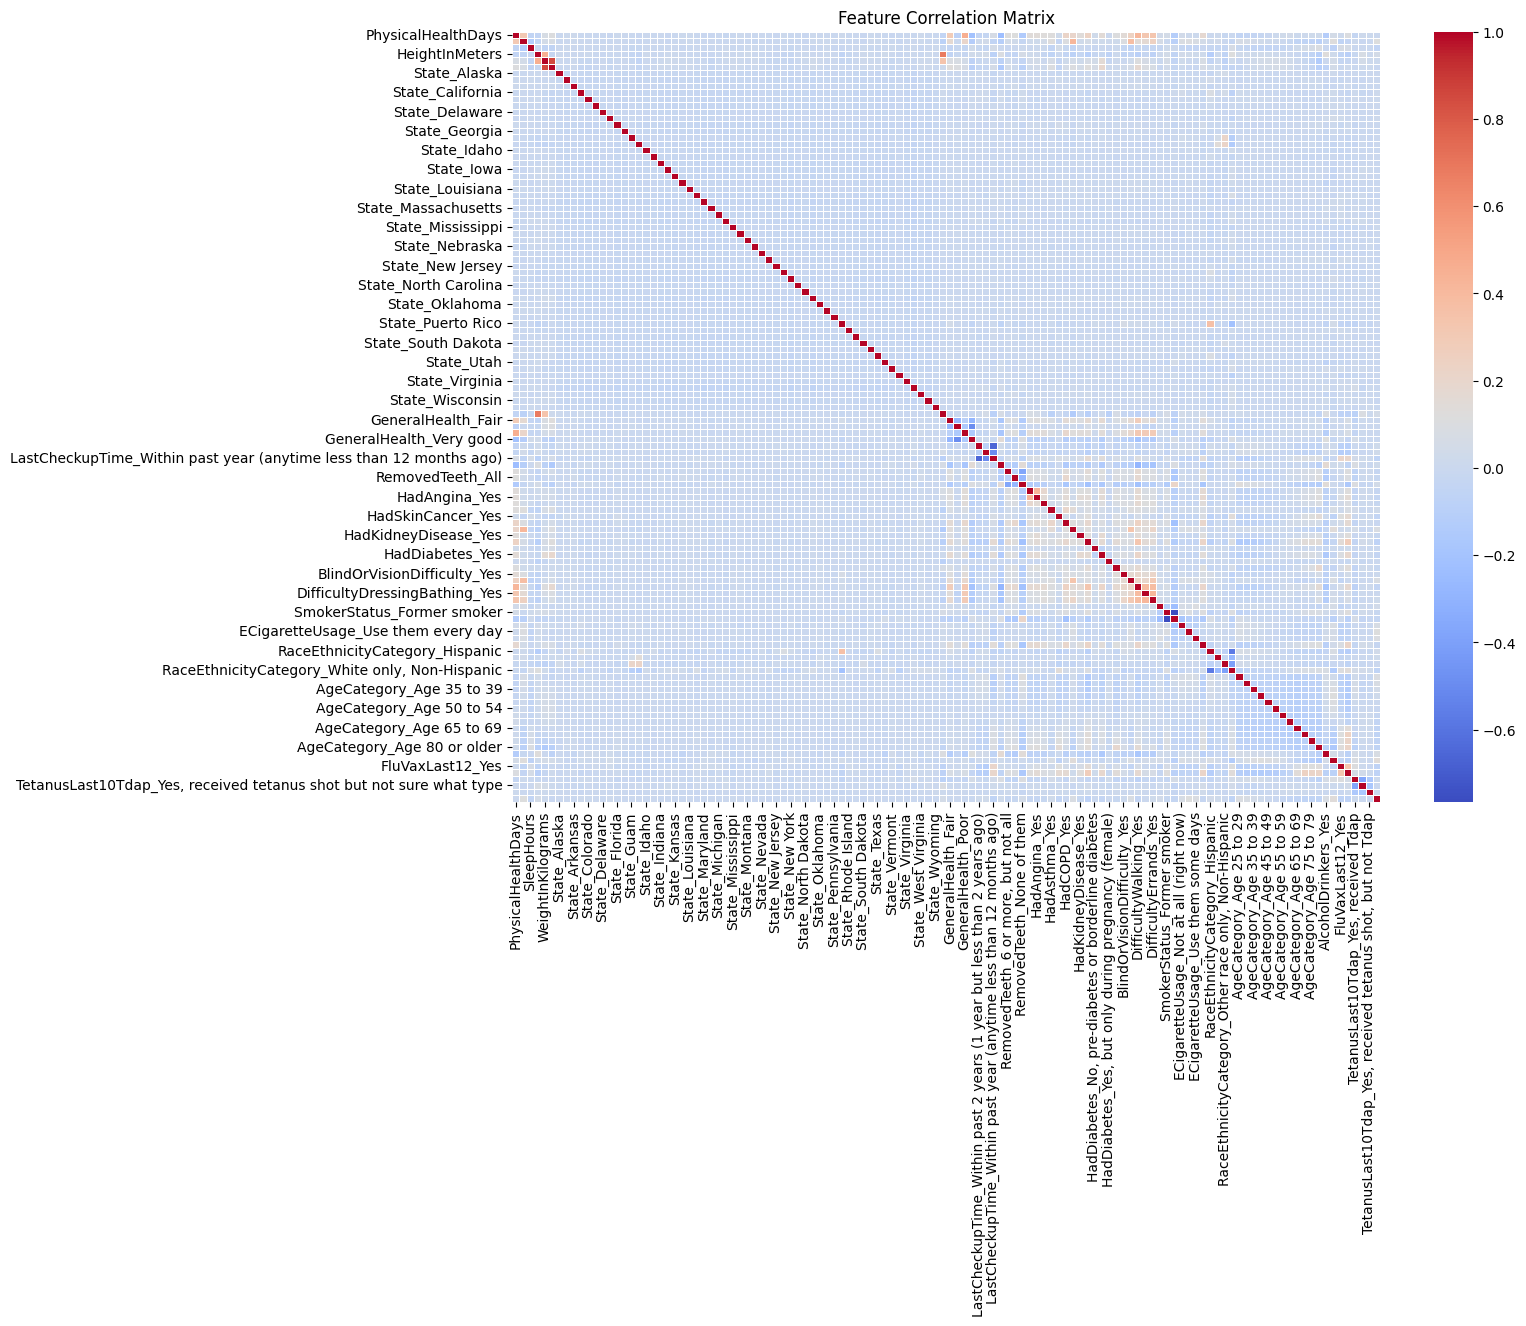

In [19]:
import seaborn as sns
feature_names = encoder.get_feature_names_out(cat_cols)
all_feature_names = list(num_cols) + list(feature_names)
X_train_df = pd.DataFrame(X_train_final, columns=all_feature_names)
correlation_matrix = X_train_df.corr()


plt.figure(figsize=(14, 10))
sns.heatmap(correlation_matrix, cmap='coolwarm', annot=False, fmt=".2f", linewidths=0.5)
plt.title('Feature Correlation Matrix')
plt.show()

In [20]:
corr_matrix = correlation_matrix.abs()

# Select the upper triangle of the matrix to ignore duplicates and the diagonal
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

#  Flatten the matrix and find pairs with a correlation higher than 0.85
high_corr_pairs = [
    (column, row, upper_tri.loc[row, column])
    for column in upper_tri.columns
    for row in upper_tri.index
    if upper_tri.loc[row, column] > 0.85
]

print("=" * 60)
print("   HIGHLY COLLINEAR FEATURE PAIRS (> 0.85)")
print("=" * 60)
if not high_corr_pairs:
    print("No features are highly collinear above 0.85!")
else:
    for feat1, feat2, value in high_corr_pairs:
        print(f"{feat1:<25} <---> {feat2:<25} | Correlation: {value:.4f}")
print("=" * 60)

   HIGHLY COLLINEAR FEATURE PAIRS (> 0.85)
BMI                       <---> WeightInKilograms         | Correlation: 0.8536


In [22]:
X_train = X_train.drop(columns=["WeightInKilograms"], errors='ignore')
X_test = X_test.drop(columns=["WeightInKilograms"], errors='ignore')

correlation with target

In [23]:
# Pandas Series -> aligns perfectly with X_train_df
y_train_series = pd.Series(y_train)

#absolute correlation of every feature against the target
target_corr = X_train_df.corrwith(y_train_series).abs()

#the noise threshold
threshold = 0.01
low_corr_features = target_corr[target_corr < threshold]

print("=" * 60)
print(f"   FEATURES WITH < {threshold * 100}% CORRELATION TO TARGET")
print("=" * 60)
if low_corr_features.empty:
    print("Every single feature has a meaningful correlation!")
else:
    print(low_corr_features.sort_values(ascending=True))
print("=" * 60)

   FEATURES WITH < 1.0% CORRELATION TO TARGET
State_Iowa                                                                 0.000006
State_Arizona                                                              0.000041
State_Kansas                                                               0.000110
State_Delaware                                                             0.000193
TetanusLast10Tdap_Yes, received tetanus shot but not sure what type        0.000454
LastCheckupTime_Within past year (anytime less than 12 months ago)         0.000572
State_Arkansas                                                             0.000636
State_North Carolina                                                       0.000757
LastCheckupTime_Within past 5 years (2 years but less than 5 years ago)    0.000915
State_Rhode Island                                                         0.000950
State_Idaho                                                                0.001135
State_Missouri                

dropping the features:

In [25]:
X_train_df = pd.DataFrame(X_train_final, columns=all_feature_names)

# Extract the exact names of the useless columns
useless_columns = list(low_corr_features.index)

# Drop them from your fully encoded training dataframe
X_train_df_pruned = X_train_df.drop(columns=useless_columns)

# CRITICAL: You must apply the exact same drop to your test set!
# First, ensure you have an X_test_df built the same way you built X_train_df:
X_test_df = pd.DataFrame(X_test_final, columns=all_feature_names)
X_test_df_pruned = X_test_df.drop(columns=useless_columns)

print(f"Dropped {len(useless_columns)} useless features.")
print(f"Final Training Shape: {X_train_df_pruned.shape}")

Dropped 46 useless features.
Final Training Shape: (315494, 74)


In [27]:
from logistic_regression import LogisticRegression
# Convert pruned data back to NumPy arrays for manual standardizer
X_train_pruned = X_train_df_pruned.values
X_test_pruned = X_test_df_pruned.values

#scale
train_mean_array = np.mean(X_train_pruned, axis=0)
train_std_array = np.std(X_train_pruned, axis=0) + 1e-8

X_train_scaled = (X_train_pruned - train_mean_array) / train_std_array
X_test_scaled = (X_test_pruned - train_mean_array) / train_std_array

print(f"Dropped {len(useless_columns)} target-irrelevant columns.")
print(f"Final Optimized Training Features Shape: {X_train_scaled.shape}")
print(f"Final Optimized Testing Features Shape: {X_test_scaled.shape}")

#train
model_slow = LogisticRegression()
model_fast = LogisticRegression()

# Train the first model
print("\nTraining model_slow (lr=0.1)...")
model_slow.fit(X_train_scaled, y_train, epochs=1000, learning_rate=0.1)

# Train the second model
print("\nTraining model_fast (lr=0.5)...")
model_fast.fit(X_train_scaled, y_train, epochs=1000, learning_rate=0.5)

Dropped 46 target-irrelevant columns.
Final Optimized Training Features Shape: (315494, 74)
Final Optimized Testing Features Shape: (78874, 74)

Training model_slow (lr=0.1)...
Epoch    0 | Loss: 0.693147
Epoch  100 | Loss: 0.600231
Epoch  200 | Loss: 0.598392
Epoch  300 | Loss: 0.598085
Epoch  400 | Loss: 0.597921
Epoch  500 | Loss: 0.597802
Epoch  600 | Loss: 0.597710
Epoch  700 | Loss: 0.597637
Epoch  800 | Loss: 0.597579
Epoch  900 | Loss: 0.597533
Training Complete | Final Loss: 0.597497

Training model_fast (lr=0.5)...
Epoch    0 | Loss: 0.693147
Epoch  100 | Loss: 0.597800
Epoch  200 | Loss: 0.597496
Epoch  300 | Loss: 0.597401
Epoch  400 | Loss: 0.597372
Epoch  500 | Loss: 0.597363
Epoch  600 | Loss: 0.597360
Epoch  700 | Loss: 0.597359
Epoch  800 | Loss: 0.597359
Epoch  900 | Loss: 0.597359
Training Complete | Final Loss: 0.597359


In [28]:
y_pred = model_fast.predict(X_test_scaled)
evaluate_model_performance(y_test, y_pred, model_label="Model with Learning Rate of 0.5")

y_pred = model_slow.predict(X_test_scaled)
evaluate_model_performance(y_test, y_pred, model_label="Model with Learning Rate of 0.1")

=== Model with Learning Rate of 0.5 ===
Accuracy:  68.7248%
Precision: 53.3402%
Recall:    6.2623%
Counts:    [TP: 1557, TN: 52649, FP: 1362, FN: 23306]

=== Model with Learning Rate of 0.1 ===
Accuracy:  68.6893%
Precision: 52.9982%
Recall:    5.9365%
Counts:    [TP: 1476, TN: 52702, FP: 1309, FN: 23387]

